In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 990.9 kB/s eta 0:00:08
   --- ------------------------------------ 0.8/8.4 MB 1.0 MB/s eta 0:00:08
   --- ------------------------------------ 0.8/8.4 MB 1.0 MB/s eta 0:00:08
   ----- ---------------------------------- 1.0/8.4 MB 986.5 kB/s eta 0:00:08
   ------ --------------------------------- 1.3/8.4 MB 1.0 MB/s eta 0:00:08
   ------- -------------------------------- 1.6/8.4 MB 1.0 MB/s eta 0:00:07
   -------- ------------------------------- 1.8/8.4 MB 1.0 MB/s eta 0:00:07
   ---------- ----------------------------- 2.1/8.4 MB 1.0 MB/s eta 0:00:07
   ---------- ----------------------------- 2.1/8.4 MB 1.0 MB/s eta 0:00:07
   ----------- ---------------------------- 2.4/8.4 MB 1.0 MB/s eta 0:00:06
   ------------ -------------

In [2]:
import sklearn
print(sklearn.__version__)

1.9.1


In [3]:
df = pd.read_csv("../Week 2/cleaned_dataset.csv")

df.head()

,sale_id,customer_name,product,category,quantity,price,city,sale_date,discount
0,1,Arun,Laptop,Electronics,1,33000.0,Bangalore,2026-08-01,10.0
1,3,Rahul,Chair,Furniture,1,4500.0,Mumbai,2026-08-05,10.0
2,4,Ananya,Keyboard,Electronics,1,2500.0,Bangalore,2026-08-07,8.0
3,5,Kiran,T-Shirt,Clothing,3,1200.0,Hyderabad,2026-08-10,15.0
4,6,Asha,Desk,Furniture,1,7000.0,Chennai,2026-08-12,10.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   sale_id        9 non-null      int64  
 1   customer_name  9 non-null      object 
 2   product        9 non-null      object 
 3   category       9 non-null      object 
 4   quantity       9 non-null      int64  
 5   price          9 non-null      float64
 6   city           9 non-null      object 
 7   sale_date      9 non-null      object 
 8   discount       9 non-null      float64
dtypes: float64(2), int64(2), object(5)
memory usage: 780.0+ bytes


In [5]:
pearson_corr = df["quantity"].corr(df["price"], method="pearson")
spearman_corr = df["quantity"].corr(df["price"], method="spearman")

print("Pearson Correlation:", pearson_corr)
print("Spearman Correlation:", spearman_corr)

Pearson Correlation: -0.42454089673650924
Spearman Correlation: -0.6390096504226938


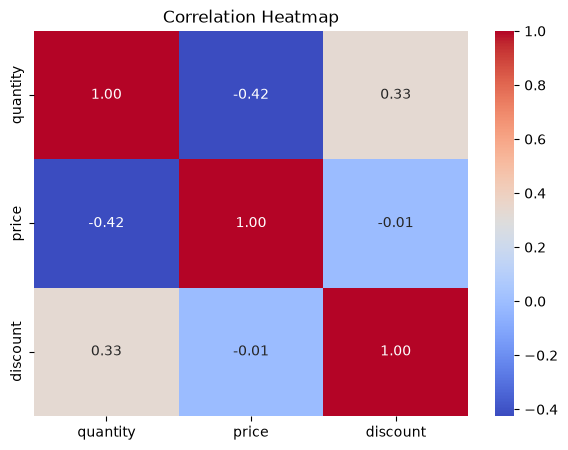

In [6]:
corr_matrix = df[["quantity", "price", "discount"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

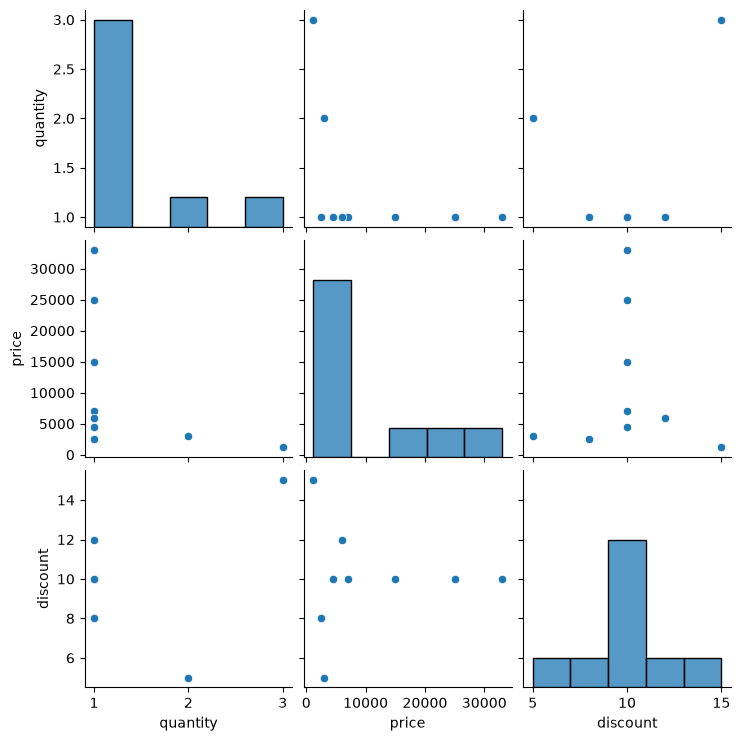

In [7]:
sns.pairplot(df[["quantity", "price", "discount"]])

plt.show()

In [8]:
X = df[["quantity"]]
y = df["price"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (9, 1)
y shape: (9,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 6
Testing samples: 3


In [10]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Coefficient: -5985.714285714284
Intercept: 17761.904761904763


In [11]:
y_pred = model.predict(X_test)

print("Actual Prices:")
print(y_test.values)

print("\nPredicted Prices:")
print(y_pred)

Actual Prices:
[15000.  4500. 25000.]

Predicted Prices:
[11776.19047619 11776.19047619 11776.19047619]


In [12]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)
print("MAE:", mae)
print("RMSE:", rmse)

R² Score: -0.13341015391089006
MAE: 7907.936507936506
RMSE: 8910.761920539408


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


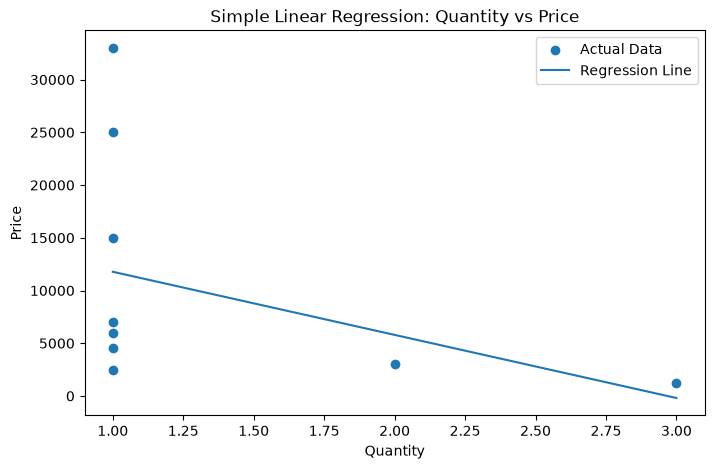

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Actual Data")

X_sorted = np.sort(X["quantity"].unique()).reshape(-1, 1)
y_line = model.predict(X_sorted)

plt.plot(X_sorted, y_line, label="Regression Line")

plt.xlabel("Quantity")
plt.ylabel("Price")
plt.title("Simple Linear Regression: Quantity vs Price")
plt.legend()
plt.show()

In [14]:
residuals = y_test - y_pred

print("Residuals:")
print(residuals.values)

Residuals:
[ 3223.80952381 -7276.19047619 13223.80952381]


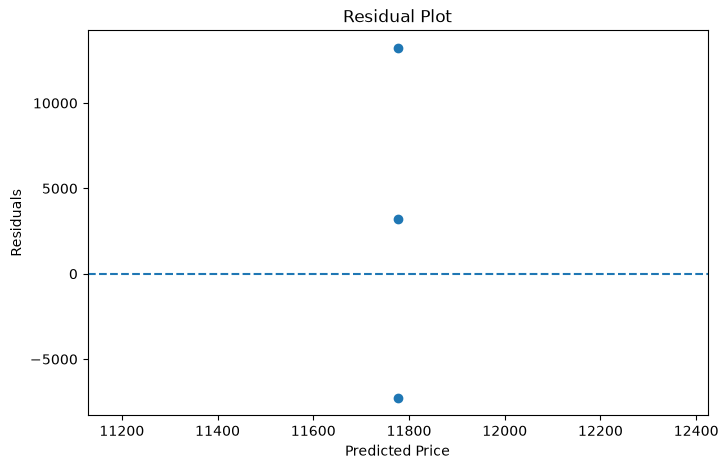

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

## Week 4 — Day 3: Regression Analysis

### Objective

Analyzed relationships between numerical variables using correlation and simple linear regression.

### Correlation Analysis

* Pearson correlation between quantity and price: **-0.4245**
* Spearman correlation between quantity and price: **-0.6390**
* Both coefficients indicate a negative association between quantity and price in this dataset.
* Correlation does not imply causation.

### Regression Model

* Predictor variable: **Quantity**
* Target variable: **Price**
* Regression coefficient: **-5985.71**
* Intercept: **17761.90**

Regression equation:

**Price = -5985.71 × Quantity + 17761.90**

### Model Evaluation

* R² Score: **-0.1334**
* MAE: **7907.94**
* RMSE: **8910.76**

The negative R² indicates that the model performs poorly on the small test set. The MAE and RMSE show that prediction errors are relatively large compared with the observed prices.

### Residual Analysis

Residuals were plotted against predicted prices to visually inspect the model errors. Because the dataset contains only 9 observations, the regression assumptions cannot be reliably validated from this sample alone.

### Key Insight

The analysis shows a negative association between quantity and price in this dataset. However, the small sample size and model performance mean that the results should be treated as an analytical exercise rather than a strong business conclusion.

### Tools Used

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Jupyter Notebook, Git and GitHub.
